In [12]:
from pathlib import Path
import json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from IPython.display import display

jax.config.update("jax_enable_x64", True)
ROOT = Path("reliable_sequential_ope_outputs")
FIG = ROOT / "figures"
TAB = ROOT / "reports"
for folder in (FIG, TAB): folder.mkdir(parents=True, exist_ok=True)
SEED = 20261107
H, GAMMA, S, A = 8, 0.97, 5, 2

## System

The transitions, rewards and reference values stay fixed across repetitions.

In [2]:
# Transition probabilities P[state, action, next_state].
P = np.zeros((S,A,S))
for s in range(S):
    for a in range(A):
        center = np.clip(s + (1 if a == 0 else -1), 0, S-1)
        P[s,a,center] += .70
        P[s,a,s] += .20
        P[s,a,np.clip(center + (1 if a == 0 else -1),0,S-1)] += .10
assert np.allclose(P.sum(axis=2), 1)
# Reward is negative operating cost. A higher value is better.
R = np.array([[-(0.3*s + 0.15*s*s + .3), -(0.3*s + 0.15*s*s + .85)] for s in range(S)])
INIT = np.array([.30,.25,.20,.15,.10])
behavior = np.column_stack([np.linspace(.68,.42,S), np.linspace(.32,.58,S)])
target = np.column_stack([np.linspace(.50,.20,S), np.linspace(.50,.80,S)])

def exact_value(policy):
    p = jnp.asarray(P); r = jnp.asarray(R); pi = jnp.asarray(policy)
    v = jnp.zeros(S)
    for _ in range(H):
        q = r + GAMMA*jnp.einsum('sak,k->sa',p,v)
        v = jnp.sum(pi*q,axis=1)
    return float(jnp.asarray(INIT) @ v)

TRUTH = exact_value(target)
print('Exact target policy value:', round(TRUTH,5))
print('Exact behavior policy value:', round(exact_value(behavior),5))

Exact target policy value: -11.0527
Exact behavior policy value: -14.00201


## Logged data

The logging policy generates the observed trajectories.

In [3]:
def simulate(n, pi, seed, noise=1.0):
    rng=np.random.default_rng(seed)
    states=np.empty((n,H+1),dtype=np.int32)
    actions=np.empty((n,H),dtype=np.int32)
    rewards=np.empty((n,H))
    states[:,0]=rng.choice(S,size=n,p=INIT)
    for t in range(H):
        s=states[:,t]
        a=(rng.random(n)>pi[s,0]).astype(np.int32)
        actions[:,t]=a
        rewards[:,t]=R[s,a]+rng.normal(0,noise,n)
        u=rng.random(n)
        cdf=np.cumsum(P[s,a,:],axis=1)
        states[:,t+1]=(u[:,None]>cdf).sum(axis=1).astype(np.int32)
    return states,actions,rewards

s,a,r=simulate(1500,behavior,SEED)
print('Episodes:',len(s),'| action frequencies:',np.bincount(a.ravel())/a.size)
print('Observed discounted reward:',np.mean(np.sum(r*GAMMA**np.arange(H),axis=1)))

Episodes: 1500 | action frequencies: [0.55608333 0.44391667]
Observed discounted reward: -13.886904467358043


## Evaluation

We fit action values on separate folds and evaluate the held-out episodes.

In [4]:
def fit_q(states, actions, rewards, target_pi, ridge=0.5):
    # Independent, time-indexed fitted Q evaluation, with pooled state-action cells.
    n=len(states)
    q=np.zeros((H,S,A)); vnext=np.zeros(S)
    for t in range(H-1,-1,-1):
        y=rewards[:,t]+GAMMA*vnext[states[:,t+1]]
        for st in range(S):
            for act in range(A):
                m=(states[:,t]==st)&(actions[:,t]==act)
                # Shrink toward the pooled reward-to-go mean to stabilize sparse cells.
                q[t,st,act]=(y[m].sum()+ridge*y.mean())/(m.sum()+ridge)
        vnext=np.sum(target_pi*q[t],axis=1)
    return q

def contributions(states,actions,rewards,bpi,tpi,q):
    n=len(states); w=np.ones(n); pd=np.zeros(n); dr=np.zeros(n)
    v=np.einsum('sa,tsa->ts',tpi,q)
    dr[:]=v[0,states[:,0]]
    for t in range(H):
        st=states[:,t]; act=actions[:,t]
        w *= tpi[st,act]/bpi[st,act]
        pd += GAMMA**t*w*rewards[:,t]
        vnext=v[t+1,states[:,t+1]] if t+1<H else np.zeros(n)
        dr += GAMMA**t*w*(rewards[:,t]+GAMMA*vnext-q[t,st,act])
    return pd,dr,w

def estimate(states,actions,rewards,bpi,tpi,folds=2):
    n=len(states); rng=np.random.default_rng(2718+n)
    perm=rng.permutation(n); groups=np.array_split(perm,folds)
    dm=np.empty(n); pd=np.empty(n); dr=np.empty(n); terminal_w=np.empty(n)
    for group in groups:
        train=np.setdiff1d(np.arange(n),group,assume_unique=True)
        q=fit_q(states[train],actions[train],rewards[train],tpi)
        dm[group]=np.sum(tpi[states[group,0]]*q[0,states[group,0]],axis=1)
        pd[group],dr[group],terminal_w[group]=contributions(states[group],actions[group],rewards[group],bpi,tpi,q)
    return {'Direct':dm,'PDIS':pd,'DR':dr},terminal_w

def summary(contrib,truth):
    x=np.asarray(contrib); est=x.mean(); se=x.std(ddof=1)/np.sqrt(len(x))
    return {'estimate':est,'se':se,'lower':est-1.96*se,'upper':est+1.96*se,
            'error':est-truth,'covered':float(abs(est-truth)<=1.96*se)}

parts,weights=estimate(s,a,r,behavior,target)
print(pd.DataFrame({k:summary(v,TRUTH) for k,v in parts.items()}).T.round(4))

        estimate      se    lower    upper   error  covered
Direct  -10.9542  0.0887 -11.1282 -10.7803  0.0985      1.0
PDIS    -10.7571  0.2039 -11.1567 -10.3574  0.2956      1.0
DR      -10.8576  0.1389 -11.1299 -10.5853  0.1951      1.0


## Overlap

The logging policy changes across three experiments. We measure the loss of effective sample size over the decision horizon.

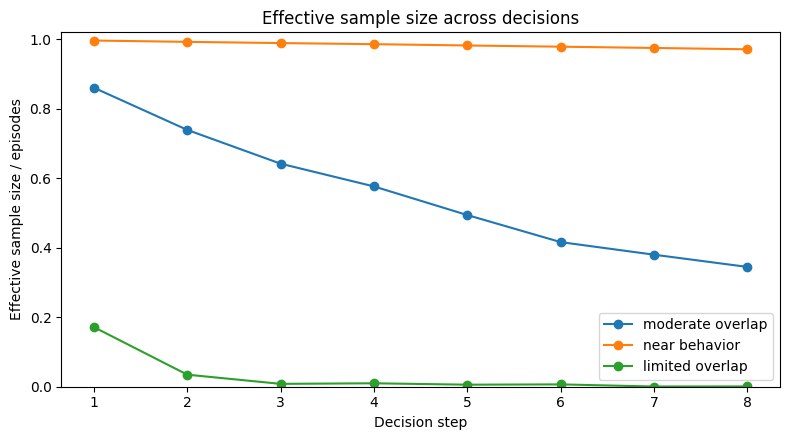

In [5]:
SCENARIOS={
 "moderate overlap":(behavior,target),
 "near behavior":(behavior,.85*behavior+.15*target),
 "limited overlap":(np.column_stack([np.linspace(.96,.88,S),np.linspace(.04,.12,S)]),target)
}
def diagnostics(states,actions,bpi,tpi):
    w=np.ones(len(states));ess=[]
    for t in range(H):
        st=states[:,t];ac=actions[:,t]
        w*=tpi[st,ac]/bpi[st,ac]
        ess.append(w.sum()**2/(np.square(w).sum()+1e-12))
    return np.array(ess),np.quantile(w,.99),w.max()
fig,ax=plt.subplots(figsize=(8,4.5))
for name,(bp,tp) in SCENARIOS.items():
    st,ac,rw=simulate(3000,bp,SEED+31)
    ess,_,_=diagnostics(st,ac,bp,tp)
    ax.plot(range(1,H+1),ess/len(st),marker='o',label=name)
ax.set(xlabel='Decision step',ylabel='Effective sample size / episodes',ylim=(0,1.02),title='Effective sample size across decisions')
ax.legend();fig.tight_layout();fig.savefig(FIG/'overlap.png',dpi=160);plt.show()

## Repeated experiments

New trajectories are generated for every repetition. We record estimation error, interval coverage and weight diagnostics.

In [6]:
REPS=45;SIZES=(400,1200);records=[]
for si,(scenario,(bp,tp)) in enumerate(SCENARIOS.items()):
    truth=exact_value(tp)
    for n in SIZES:
        for rep in range(REPS):
            st,ac,rw=simulate(n,bp,SEED+100000*si+1000*n+rep)
            estimates,_=estimate(st,ac,rw,bp,tp,folds=3)
            ess,p99,wmax=diagnostics(st,ac,bp,tp)
            for method,values in estimates.items():
                records.append(dict(scenario=scenario,n=n,rep=rep,method=method,truth=truth,
                    ess_fraction=ess[-1]/n,weight_p99=p99,weight_max=wmax,**summary(values,truth)))
results=pd.DataFrame(records)
results.to_csv(TAB/'replications.csv',index=False)
print('Independent datasets:',len(results)//3)
display(results.head().round(4))

Independent datasets: 270


,scenario,n,rep,method,truth,ess_fraction,weight_p99,weight_max,estimate,se,lower,upper,error,covered
0,moderate overlap,400,0,Direct,-11.0527,0.2582,7.5366,16.7187,-10.7940,0.1721,-11.1313,-10.4566,0.2587,1.0
1,moderate overlap,400,0,PDIS,-11.0527,0.2582,7.5366,16.7187,-10.7234,0.4012,-11.5097,-9.9371,0.3293,1.0
2,moderate overlap,400,0,DR,-11.0527,0.2582,7.5366,16.7187,-10.5277,0.3017,-11.1190,-9.9364,0.5250,1.0
3,moderate overlap,400,1,Direct,-11.0527,0.2848,6.6481,15.2748,-11.1499,0.1628,-11.4690,-10.8308,-0.0972,1.0
4,moderate overlap,400,1,PDIS,-11.0527,0.2848,6.6481,15.2748,-10.8863,0.4002,-11.6707,-10.1019,0.1664,1.0


## Accuracy

RMSE, bias and confidence interval coverage are calculated against exact policy values.

,scenario,n,method,bias,rmse,coverage,mean_se,median_ess
0,limited overlap,400,DR,-0.9463,13.7120,0.3778,5.0901,0.0125
1,limited overlap,400,Direct,-6.8711,6.8953,0.0000,0.1029,0.0125
2,limited overlap,400,PDIS,0.5883,4.3438,0.7778,3.3933,0.0125
3,limited overlap,1200,DR,-2.1608,4.0372,0.3778,2.2212,0.0042
4,limited overlap,1200,Direct,-5.1843,5.1930,0.0000,0.0722,0.0042
5,limited overlap,1200,PDIS,1.0384,4.0740,0.5111,2.4676,0.0042
6,moderate overlap,400,DR,0.0791,0.3508,0.9111,0.2861,0.3242
7,moderate overlap,400,Direct,-0.1403,0.3471,0.6222,0.1657,0.3242
8,moderate overlap,400,PDIS,0.1281,0.4423,0.9111,0.4080,0.3242
9,moderate overlap,1200,DR,-0.0313,0.1836,0.9111,0.1631,0.3276


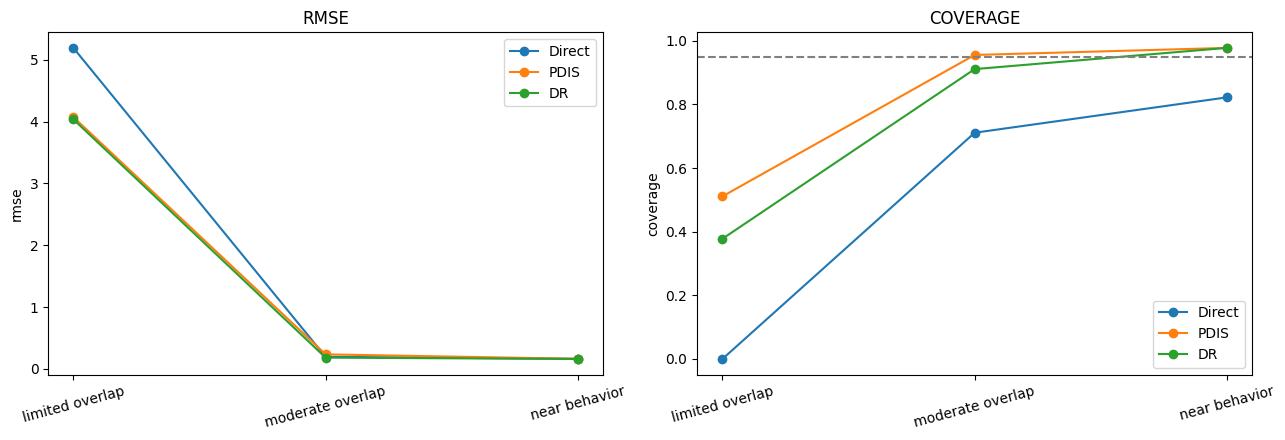

In [7]:
metrics=results.groupby(['scenario','n','method']).agg(
    bias=('error','mean'),rmse=('error',lambda x:np.sqrt(np.mean(np.square(x)))),
    coverage=('covered','mean'),mean_se=('se','mean'),median_ess=('ess_fraction','median')).reset_index()
metrics.to_csv(TAB/'metrics.csv',index=False)
display(metrics.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for j,metric in enumerate(['rmse','coverage']):
    ax=axes[j];d=metrics[metrics.n==1200]
    for method in ('Direct','PDIS','DR'):
        sub=d[d.method==method]
        ax.plot(sub.scenario,sub[metric],marker='o',label=method)
    if metric=='coverage':ax.axhline(.95,linestyle='--',color='gray')
    ax.set(title=metric.upper(),ylabel=metric);ax.tick_params(axis='x',rotation=15);ax.legend()
fig.tight_layout();fig.savefig(FIG/'accuracy.png',dpi=160);plt.show()

## Confidence interval checks

Wilson intervals show the sampling uncertainty of the measured coverage rates.

,scenario,n,method,coverage,lower,upper
3,limited overlap,1200,DR,0.378,0.251,0.524
4,limited overlap,1200,Direct,0.000,0.000,0.079
5,limited overlap,1200,PDIS,0.511,0.370,0.650
9,moderate overlap,1200,DR,0.911,0.793,0.965
10,moderate overlap,1200,Direct,0.711,0.566,0.823
11,moderate overlap,1200,PDIS,0.956,0.852,0.988
15,near behavior,1200,DR,0.978,0.884,0.996
16,near behavior,1200,Direct,0.822,0.687,0.907
17,near behavior,1200,PDIS,0.978,0.884,0.996


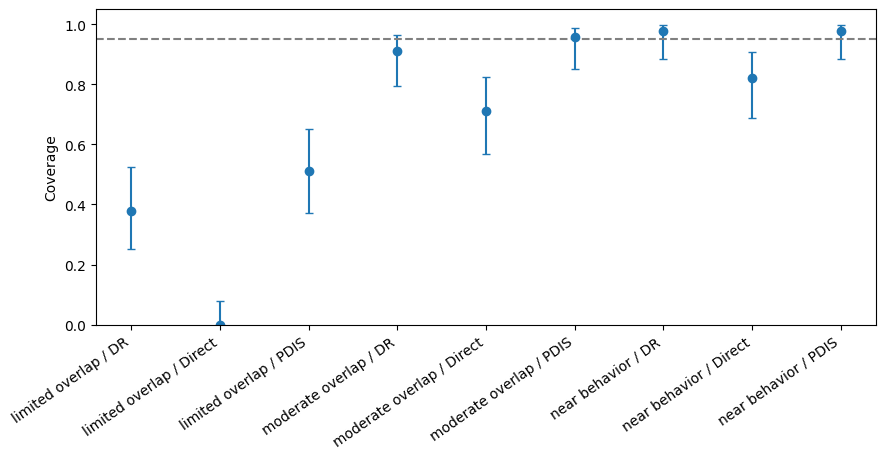

In [8]:
def wilson(k,n,z=1.96):
    p=k/n;den=1+z*z/n;center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half
coverage=[]
for (scenario,n,method),g in results.groupby(['scenario','n','method']):
    lo,hi=wilson(int(g.covered.sum()),len(g))
    coverage.append(dict(scenario=scenario,n=n,method=method,coverage=g.covered.mean(),lower=lo,upper=hi))
coverage=pd.DataFrame(coverage);coverage.to_csv(TAB/'coverage_intervals.csv',index=False)
display(coverage[coverage.n==1200].round(3))
fig,ax=plt.subplots(figsize=(9,4.7));d=coverage[coverage.n==1200];x=np.arange(len(d))
ax.errorbar(x,d.coverage,yerr=[d.coverage-d.lower,d.upper-d.coverage],fmt='o',capsize=3)
ax.axhline(.95,color='gray',linestyle='--');ax.set(xticks=x,xticklabels=[f'{s} / {m}' for s,m in zip(d.scenario,d.method)],ylabel='Coverage',ylim=(0,1.05))
plt.setp(ax.get_xticklabels(),rotation=35,ha='right');fig.tight_layout();fig.savefig(FIG/'coverage.png',dpi=160);plt.show()

## Support screen

We flag evaluations with very low effective sample size. The threshold is a diagnostic choice, not a coverage guarantee.

,scenario,n,support_rate,rmse_all,rmse_supported,coverage_supported,retained
0,limited overlap,400,0.0,13.7120,NaN,NaN,0.0
1,limited overlap,1200,0.0,4.0372,NaN,NaN,0.0
2,moderate overlap,400,1.0,0.3508,0.3508,0.9111,45.0
3,moderate overlap,1200,1.0,0.1836,0.1836,0.9111,45.0
4,near behavior,400,1.0,0.2759,0.2759,0.9778,45.0
5,near behavior,1200,1.0,0.1616,0.1616,0.9778,45.0


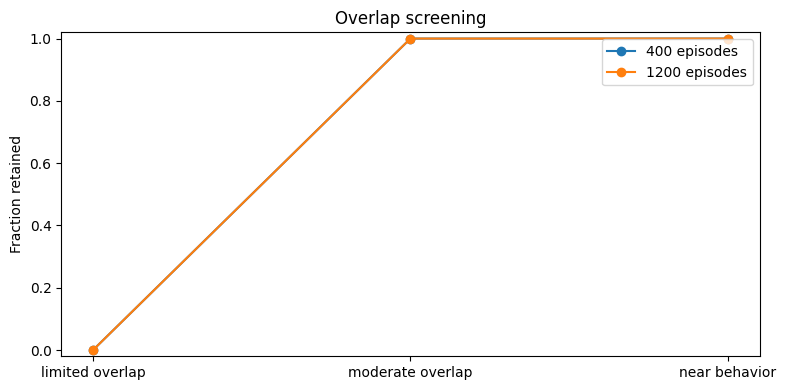

In [9]:
THRESHOLD=.10;dr=results[results.method=='DR'].copy();dr['supported']=dr.ess_fraction>=THRESHOLD
screen=dr.groupby(['scenario','n']).apply(lambda g:pd.Series({
    'support_rate':g.supported.mean(),'rmse_all':np.sqrt(np.mean(g.error**2)),
    'rmse_supported':np.sqrt(np.mean(g.loc[g.supported,'error']**2)) if g.supported.any() else np.nan,
    'coverage_supported':g.loc[g.supported,'covered'].mean() if g.supported.any() else np.nan,
    'retained':int(g.supported.sum())}),include_groups=False).reset_index()
screen.to_csv(TAB/'support_screen.csv',index=False);display(screen.round(4))
fig,ax=plt.subplots(figsize=(8,4))
for n in SIZES:
    d=screen[screen.n==n];ax.plot(d.scenario,d.support_rate,marker='o',label=str(n)+' episodes')
ax.set(ylabel='Fraction retained',ylim=(-.02,1.02),title='Overlap screening');ax.legend()
fig.tight_layout();fig.savefig(FIG/'support.png',dpi=160);plt.show()

## Error distributions

The repeated estimates reveal the spread of errors across overlap settings.

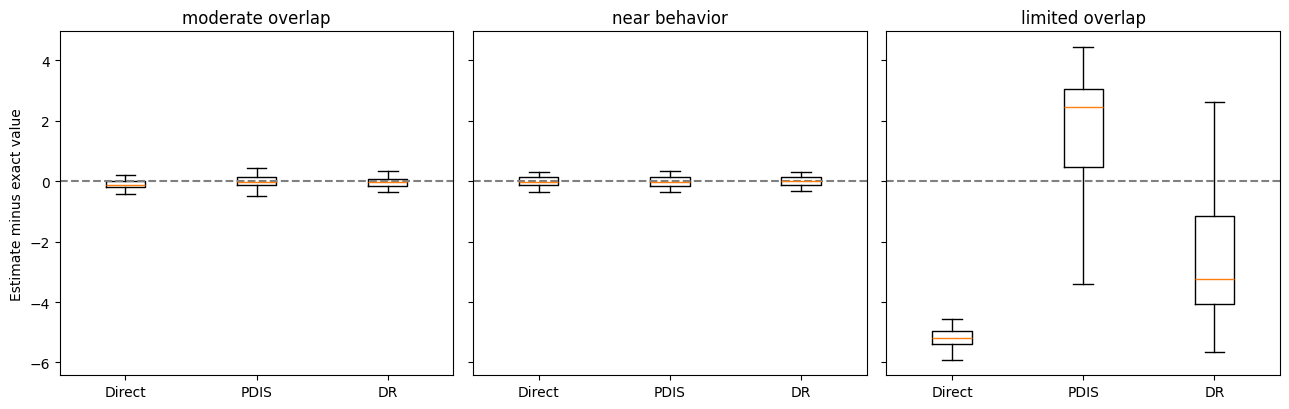

In [10]:
fig,axes=plt.subplots(1,3,figsize=(13,4.2),sharey=True)
for ax,scenario in zip(axes,SCENARIOS):
    d=results[(results.scenario==scenario)&(results.n==1200)]
    ax.boxplot([d[d.method==method].error for method in ('Direct','PDIS','DR')],tick_labels=['Direct','PDIS','DR'],showfliers=False)
    ax.axhline(0,color='gray',linestyle='--');ax.set_title(scenario)
axes[0].set_ylabel('Estimate minus exact value');fig.tight_layout();fig.savefig(FIG/'errors.png',dpi=160);plt.show()

## Saved results

The checks confirm the experiment counts and probability distributions. Tables and figures are ready for review.

In [11]:
assert np.allclose(P.sum(axis=-1),1)
assert all(np.allclose(pi.sum(axis=1),1) for pair in SCENARIOS.values() for pi in pair)
assert len(results)==len(SCENARIOS)*len(SIZES)*REPS*3
assert np.isfinite(results[['estimate','se','error']].to_numpy()).all()
metadata={'seed':SEED,'horizon':H,'discount':GAMMA,'repetitions':REPS,'sizes':SIZES,
 'scenarios':list(SCENARIOS),'estimators':['Direct','PDIS','DR'],
 'interval':'episode-level normal approximation','ess_screen_threshold':THRESHOLD,
 'jax_version':jax.__version__,'numpy_version':np.__version__}
(TAB/'metadata.json').write_text(json.dumps(metadata,indent=2))
print('Checks passed. Figures:',len(list(FIG.glob('*.png'))),'Reports:',len(list(TAB.iterdir())))

Checks passed. Figures: 5 Reports: 5
